# 9-4. 로그 스케일 -- 리샘플링 vs 자체 7분위 구간 비교

**전체 계획** (auto_arima만 사용, GARCH/SV는 나중에)

1. d 고정 (`9-1`: d=1)
2. auto_arima로 p,q 선택 (`9-2`: AICc)
3. 원 스케일: 리샘플링 vs 자체 7분위 비교 (`9-3`)
4. **로그 스케일: 리샘플링 vs 자체 7분위 비교** (이 노트북)

**공통 조건**: CRPS는 구간의 7분위(10·20·30·50·70·80·90%)로 계산한다.

**방법**: `100 x log(y)`에 `auto_arima`(d=1, AICc)를 적용하고 구간을 `exp`로 되돌려 **원 스케일에서 채점**한다.
- 분위수는 단조변환에 그대로 따라가서 `exp(q/100)`이 원 스케일 분위수다.
- 자체: 로그 스케일 정규 구간(원 스케일에서는 비대칭). 리샘플링: 로그 스케일 과거 오차 표본(500개, 중앙값을 빼서 중심화) + 점예측 후 `exp`. auto_arima는 분산이 일정해 원 오차를 그대로 쓴다(GARCH·SV는 `9-6`~`9-9`에서 σ_h로 표준화한 오차를 쓴다).
- MSE의 점예측은 중앙값 `exp(μ)`이고, 평균 보정은 참고로 본다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats
from statsmodels.tsa.stattools import kpss, adfuller

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, SCALE = 1, 500, 100.0

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()                     # 원 스케일 표준편차(지표 정규화에 원 스케일 기준을 그대로 쓴다)
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


print(f"전체 origin {len(origins)}개, 채점 origin {len(scored_origins)}개")
print("첫 채점 origin:", label(scored_origins[0]))
print("마지막 채점 origin:", label(scored_origins[-1]))
_, kp, _, _ = kpss(LOG, regression="c", nlags="auto")
_, kpd, _, _ = kpss(np.diff(LOG), regression="c", nlags="auto")
print(f"참고 -- 로그 시계열(전체 60개) KPSS p: 수준 {kp:.3f}, 차분 {kpd:.3f} / ADF p: 수준 {adfuller(LOG)[1]:.3f}, 차분 {adfuller(np.diff(LOG))[1]:.4f}")


전체 origin 37개, 채점 origin 22개
첫 채점 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 채점 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)
참고 -- 로그 시계열(전체 60개) KPSS p: 수준 0.043, 차분 0.100 / ADF p: 수준 0.126, 차분 0.0117


C:\Users\Administrator\AppData\Local\Temp\ipykernel_4776\1497583976.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kpd, _, _ = kpss(np.diff(LOG), regression="c", nlags="auto")


## 1. 로그 스케일에서 두 구간 만들기

각 origin에서 `auto_arima`(d=1 고정, p,q는 AICc)를 로그 시계열로 fit하고 두 구간을 `exp`로 원 스케일에 되돌린다. d=1은 원 스케일에서 정한 값을 그대로 쓴다(로그 시계열도 KPSS·ADF가 같은 방향).

- 커버리지: 90% 구간을 `exp`로 되돌려 원 스케일 실제값 적중 여부를 본다.
- CRPS(7분위): 되돌린 7분위로 원 스케일에서 계산한다.

In [2]:
def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


def self_quantiles(m):
    fc = np.asarray(m.predict(n_periods=H))
    q = {0.5: fc}
    for alpha in (0.2, 0.4, 0.6):
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=alpha)
        q[round(alpha / 2, 1)], q[round(1 - alpha / 2, 1)] = conf[:, 0], conf[:, 1]
    _, c90 = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return fc, np.array([q[t] for t in LEVELS]), c90


CACHE = "../cache/cache_94_log_resample_vs_self_df.pkl"
if os.path.exists(CACHE) and "pool_std" in pd.read_pickle(CACHE).columns:
    logres = pd.read_pickle(CACHE)
    print(f"캐시에서 로드: {len(logres)}행")
else:
    rng = rng_for("X3_l1_9-4_log_resample_vs_self")
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        train, actual = LOG[:o], vals[o:o + H]
        m = pm.auto_arima(train, d=D, seasonal=False, information_criterion="aicc", suppress_warnings=True, error_action="ignore")
        fc, q7_self, c90 = self_quantiles(m)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                samples = fc[h - 1] + rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)   # 로그 스케일, 오차 중심화
                q7_res = to_orig(np.quantile(samples, LEVELS))
                lo_r, hi_r = to_orig(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                sig = max((c90[h - 1, 1] - c90[h - 1, 0]) / (2 * Z), 1e-6)                          # 로그 스케일 100배 단위
                med = float(to_orig(fc[h - 1]))
                mean_self = float(np.exp(fc[h - 1] / SCALE + (sig / SCALE) ** 2 / 2))
                mean_res = float(to_orig(samples).mean())
                rows.append({"origin": o, "h": h, "방식": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100,
                             "MSE": ((a - med) / var_std) ** 2, "MSE(평균 보정, 참고)": ((a - mean_res) / var_std) ** 2,
                             "CRPS(7분위)": crps7(q7_res, a),
                             "구간폭": (hi_r - lo_r) / var_std, "lo": lo_r, "hi": hi_r, "fc": med, "actual": a,
                             "pool_n": len(pool[h]), "pool_std": pool[h].std(), "pool_absmax": np.abs(pool[h]).max()})
                lo_n, hi_n = to_orig(c90[h - 1])
                rows.append({"origin": o, "h": h, "방식": "자체", "적중": float(lo_n <= a <= hi_n) * 100,
                             "MSE": ((a - med) / var_std) ** 2, "MSE(평균 보정, 참고)": ((a - mean_self) / var_std) ** 2,
                             "CRPS(7분위)": crps7(to_orig(q7_self[:, h - 1]), a),
                             "구간폭": (hi_n - lo_n) / var_std, "lo": lo_n, "hi": hi_n, "fc": med, "actual": a, "sigma_model": sig})
        for h in range(1, H + 1):
            pool[h] = np.append(pool[h], np.log(actual[h - 1]) * SCALE - fc[h - 1])
    logres = pd.DataFrame(rows)
    logres.to_pickle(CACHE)
    print(f"계산 완료: {len(logres)}행 (origin {logres['origin'].nunique()}개 x h {H} x 방식 2)")


캐시에서 로드: 176행


## 2. 결과 -- 로그 스케일 22개 origin 전체 평균

22개 origin x h=1~4 = 88개를 방식별로 평균한다. 로그 스케일에서 리샘플링의 과거 오차 표본은 **중앙값을 빼서 중심화**한 뒤 점예측 `exp(μ)`에 더한다. 그래서 두 방식의 점예측이 모두 `exp(μ)`로 같고 MSE도 같다(원 스케일과 같은 구조).

중심화하지 않으면 과거 오차의 치우침만큼 리샘플링 구간 전체가 이동해, 구간 방식의 차이에 점예측 보정 효과가 섞인다. 그래서 원 스케일과 로그 스케일 모두 오차 표본을 중심화한다.

In [3]:
cols = ["적중", "MSE", "MSE(평균 보정, 참고)", "CRPS(7분위)", "구간폭"]
log_sum = logres.groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"}).round(3)
display(log_sum)
print("h별 (로그 스케일):")
display(logres.groupby(["방식", "h"])[["적중", "CRPS(7분위)", "구간폭"]].mean().rename(columns={"적중": "커버리지(%)"}).round(3).unstack("방식"))


,커버리지(%),MSE,"MSE(평균 보정, 참고)",CRPS(7분위),구간폭
방식,,,,,
리샘플링,77.273,1.802,4.236,0.841,6.164
자체,75.000,1.802,2.560,0.767,4.070


h별 (로그 스케일):


커버리지(%)         CRPS(7분위)           구간폭       
방식    리샘플링      자체      리샘플링     자체   리샘플링     자체
h                                                
1   77.273  77.273     0.345  0.336  2.056  1.452
2   72.727  72.727     0.687  0.613  4.736  3.043
3   77.273  72.727     1.045  0.929  8.057  4.874
4   81.818  77.273     1.286  1.188  9.807  6.912

### 2-1. 로그 시계열에서 선택된 (p,d,q)

로그 시계열에서는 `auto_arima`가 원 스케일과 다른 차수를 고를 수 있다. 선택된 차수를 확인한다(원 스케일은 `9-2`의 AICc 결과).


In [4]:
ord_rows = []
for o in scored_origins:
    m = pm.auto_arima(LOG[:o], d=D, seasonal=False, information_criterion="aicc", suppress_warnings=True, error_action="ignore")
    ord_rows.append({"origin": o, "훈련 기간": f"{quarters[0]}~{quarters[o - 1]}", "예측 기간": f"{quarters[o]}~{quarters[o + H - 1]}",
                     "로그 시계열 (p,d,q)": m.order, "절편": m.with_intercept})
ord_df = pd.DataFrame(ord_rows).set_index("origin")
orig_orders = pd.read_pickle("../cache/cache_92_ic_q7_df.pkl").xs("aicc", level="ic")["order"]
ord_df.insert(2, "원 스케일 (p,d,q)", orig_orders)
display(ord_df)
print("선택된 차수 분포 -- 원 스케일:", orig_orders.value_counts().to_dict())
print("선택된 차수 분포 -- 로그 스케일:", ord_df["로그 시계열 (p,d,q)"].value_counts().to_dict())
print("절편 포함:", int(ord_df["절편"].sum()), "/", len(ord_df))


,훈련 기간,예측 기간,"원 스케일 (p,d,q)","로그 시계열 (p,d,q)",절편
origin,,,,,
35,2011Q1~2019Q3,2019Q4~2020Q3,"(1, 1, 0)","(2, 1, 0)",False
36,2011Q1~2019Q4,2020Q1~2020Q4,"(1, 1, 0)","(2, 1, 0)",False
37,2011Q1~2020Q1,2020Q2~2021Q1,"(1, 1, 0)","(2, 1, 0)",False
38,2011Q1~2020Q2,2020Q3~2021Q2,"(1, 1, 0)","(2, 1, 0)",False
39,2011Q1~2020Q3,2020Q4~2021Q3,"(1, 1, 0)","(2, 1, 0)",False
40,2011Q1~2020Q4,2021Q1~2021Q4,"(1, 1, 0)","(2, 1, 0)",False
41,2011Q1~2021Q1,2021Q2~2022Q1,"(1, 1, 0)","(1, 1, 1)",False
42,2011Q1~2021Q2,2021Q3~2022Q2,"(1, 1, 0)","(1, 1, 0)",False
43,2011Q1~2021Q3,2021Q4~2022Q3,"(1, 1, 0)","(1, 1, 0)",False


선택된 차수 분포 -- 원 스케일: {(1, 1, 0): 17, (0, 1, 1): 2, (2, 1, 0): 2, (2, 1, 1): 1}
선택된 차수 분포 -- 로그 스케일: {(1, 1, 0): 10, (2, 1, 0): 6, (3, 1, 2): 3, (1, 1, 1): 1, (0, 1, 2): 1, (2, 1, 2): 1}
절편 포함: 1 / 22


## 3. 원 스케일(`9-3`)과 로그 스케일 비교 -- 4가지 조합


In [5]:
orig = pd.read_pickle("../cache/cache_93_resample_vs_self_df.pkl")
orig_sum = orig.groupby("방식")[["적중", "MSE", "CRPS(7분위)", "구간폭"]].mean().rename(columns={"적중": "커버리지(%)"})
tab = pd.concat({"원 스케일": orig_sum, "로그 스케일": log_sum.drop(columns=["MSE(평균 보정, 참고)"])}, names=["스케일", "방식"]).round(3)

# 구간 폭이 원 스케일의 몇 배가 되었는지 (같은 방식끼리 비교)
mult = (tab.loc["로그 스케일", "구간폭"] / tab.loc["원 스케일", "구간폭"]).round(2)
tab["폭 배율(원 대비)"] = np.nan
tab.loc["로그 스케일", "폭 배율(원 대비)"] = mult.values
display(tab.style
        .format({"폭 배율(원 대비)": "x{:.2f}"}, na_rep="")
        .set_properties(subset=pd.IndexSlice["로그 스케일", ["구간폭", "폭 배율(원 대비)"]],
                        **{"background-color": "#FFF1D6", "color": "#B45F06", "font-weight": "bold"}))


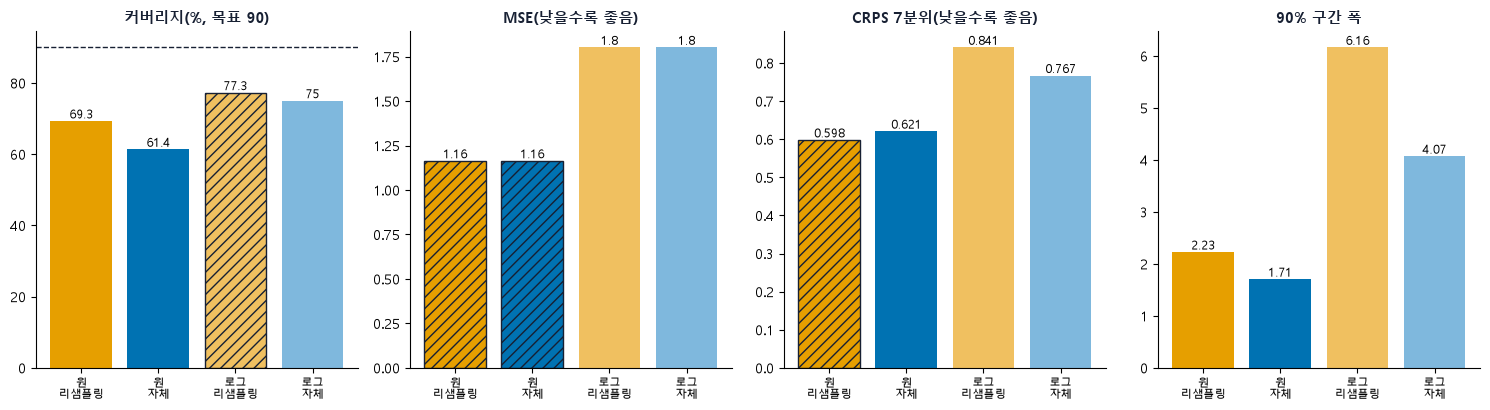

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

combos = [("원 스케일", "리샘플링"), ("원 스케일", "자체"), ("로그 스케일", "리샘플링"), ("로그 스케일", "자체")]
colr = {("원 스케일", "리샘플링"): "#E69F00", ("원 스케일", "자체"): "#0072B2", ("로그 스케일", "리샘플링"): "#F0C060", ("로그 스케일", "자체"): "#7FB8DD"}
names = ["원\n리샘플링", "원\n자체", "로그\n리샘플링", "로그\n자체"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("구간폭", "90% 구간 폭")]):
    vals_ = [tab.loc[k, c] for k in combos]
    bars = ax.bar(names, vals_, color=[colr[k] for k in combos])
    if c != "구간폭":   # 폭은 좋고 나쁨이 없어 1등 표시를 하지 않는다
        sc = np.abs(np.array(vals_) - 90) if c.startswith("커버리지") else np.array(vals_)
        for b, s_ in zip(bars, sc):
            if s_ <= sc.min() + 1e-9:   # 1등(동률이면 모두)에 빗금
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
    ax.tick_params(axis="x", labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 4. origin별 추이

로그 스케일의 두 방식을 origin별로 본다(origin당 h=1~4 평균). 원 스케일과의 비교는 위 3절 표와 그림이다. 평가는 위의 22개 전체 평균이고, 이 그림은 차이가 어디서 생기는지 보는 용도다.


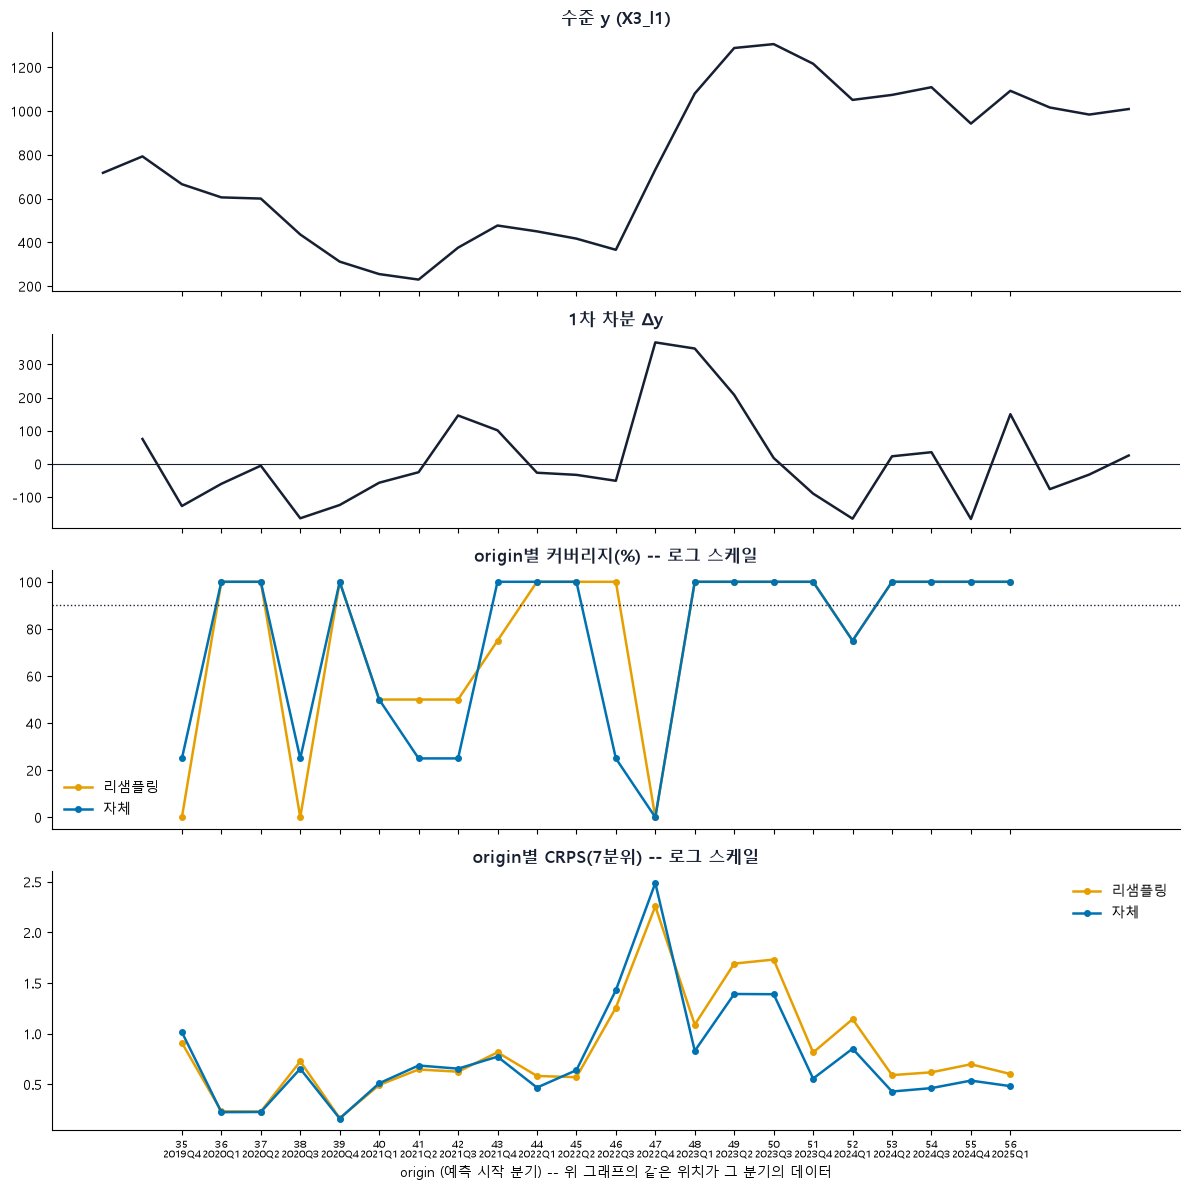

In [7]:
per_log = logres.groupby(["방식", "origin"])[["적중", "CRPS(7분위)"]].mean()
xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.2, 1.6, 1.6]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
lines = [("리샘플링", per_log.loc["리샘플링"], "#E69F00", "-"), ("자체", per_log.loc["자체"], "#0072B2", "-")]
for ax, c, t in [(axes[2], "적중", "origin별 커버리지(%) -- 로그 스케일"), (axes[3], "CRPS(7분위)", "origin별 CRPS(7분위) -- 로그 스케일")]:
    for nm, d_, col, ls in lines:
        ax.plot(scored_origins, d_[c].values, marker="o", ms=4, color=col, linestyle=ls, linewidth=1.8, label=nm)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.legend(frameon=False)
axes[2].axhline(90, color="#172033", linestyle=":", linewidth=1)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


## 5. 결론

**auto_arima에서는 로그변환이 커버리지만 올리고 정확도(MSE, CRPS)는 크게 나빠진다. 로그변환이 무조건 좋지는 않다(GARCH·SV에서는 `9-7`, `9-9`에서 따로 확인).**

| 스케일 | 방식 | 커버리지(%) | MSE | CRPS(7분위) | 90% 구간 폭 |
|---|---|---|---|---|---|
| 원 | 리샘플링 | 69.3 | 1.164 | 0.598 | 2.23 |
| 원 | 자체 | 61.4 | 1.164 | 0.621 | 1.71 |
| 로그 | 리샘플링 | 77.3 | 1.802 | 0.841 | 6.16 |
| 로그 | 자체 | 75.0 | 1.802 | 0.767 | 4.07 |

- **커버리지는 오르지만** 목표 90%에는 못 미친다.
- **구간이 2.4~2.8배 넓어진다**(`exp`로 되돌리면 위쪽이 길게 늘어남). 커버리지 상승의 상당 부분이 폭의 대가다.
- **CRPS 악화**: 리샘플링 +41%, 자체 +24%. 먼 h일수록 격차가 크다. **MSE도 악화**(리샘플링 오차 표본을 중심화해 두 방식의 점예측이 같음. 평균 보정은 더 나쁨: 4.24/2.56).
- **로그에서는 자체가 리샘플링보다 낫다**(CRPS 0.767 vs 0.841). 원 스케일과 순위가 뒤바뀐다.
- **차수의 영향도 섞여 있다**: 로그 시계열에서 auto_arima가 (1,1,0) 10개, (2,1,0) 6개, (3,1,2) 3개 등 복잡한 모델을 많이 골랐다(원 스케일은 (1,1,0) 17개). 수준이 낮은 구간에서 AR(2)가 추세를 이어받아 크게 빗나간 origin이 있다. 8-5에서 AR(1) 고정으로도 로그 CRPS가 나빠져 방향은 같다.

**한계**: 선택된 차수가 달라 변환의 순수한 효과만 분리하지 못했다. 22개 origin이 겹쳐 유의성은 검증하지 않았다.

## 6. 두 방식의 차이 분석 (추가 연구)

리샘플링과 자체 구간의 차이가 **실제로 있는지, 폭 때문인지** 본다. 검정은 쓰지 않는다.

1. **짝지은 차이**: origin별 (리샘플링 - 자체)로 일관성과 쏠림을 본다.
2. **같은 폭에서 비교**: 구간 점수(α=0.10)는 `폭 + (2/α) x (실제값이 구간 밖으로 벗어난 거리)`를 `var_std`로 나눈 값이다 (Gneiting & Raftery, 2007의 interval score를 α=0.10으로 적용)(낮을수록 좋음, 벗어난 거리에 20배 벌점). 그리고  88개 커버리지를 90%에 맞추는 최소 배율 k와 그때의 폭.

In [8]:
DF = logres.copy()
ALPHA_IS = 0.10
DF["구간점수"] = ((DF["hi"] - DF["lo"]) + (2 / ALPHA_IS) * np.maximum(DF["lo"] - DF["actual"], 0)
              + (2 / ALPHA_IS) * np.maximum(DF["actual"] - DF["hi"], 0)) / var_std

po = DF.groupby(["방식", "origin"])[["CRPS(7분위)", "구간점수", "적중", "구간폭"]].mean()
dif = po.loc["리샘플링"] - po.loc["자체"]        # 리샘플링 - 자체 (origin별)
rows = []
for c, better in [("CRPS(7분위)", "neg"), ("구간점수", "neg"), ("적중", "pos")]:
    d_ = dif[c]
    n_better = int((d_ < -1e-9).sum()) if better == "neg" else int((d_ > 1e-9).sum())
    n_worse = int((d_ > 1e-9).sum()) if better == "neg" else int((d_ < -1e-9).sum())
    rows.append({"지표": c.replace("적중", "커버리지(%)"), "평균 차이": d_.mean(), "중앙값 차이": d_.median(),
                 "리샘플링이 앞선 origin": n_better, "뒤진 origin": n_worse, "같은 origin": len(d_) - n_better - n_worse})
display(pd.DataFrame(rows).set_index("지표").round(3))
print("차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.")

split = np.where(dif.index <= 46, "origin 35~46 (예측 시작 2022Q3 이전)", "origin 47~56 (2022Q4 이후)")
print("구간별 평균 차이 (리샘플링 - 자체):")
display(dif.groupby(split).mean().rename(columns={"적중": "커버리지(%)"}).round(3))
hdiff = (DF[DF["방식"] == "리샘플링"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean()
         - DF[DF["방식"] == "자체"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean())
print("h별 평균 차이 (리샘플링 - 자체):")
display(hdiff.rename(columns={"적중": "커버리지(%)"}).round(3))


,평균 차이,중앙값 차이,리샘플링이 앞선 origin,뒤진 origin,같은 origin
지표,,,,,
CRPS(7분위),0.074,0.058,7,15,0
구간점수,0.989,2.046,5,17,0
커버리지(%),2.273,0.000,3,3,16


차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.
구간별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%),구간폭
origin 35~46 (예측 시작 2022Q3 이전),-0.016,-0.553,4.167,0.446
origin 47~56 (2022Q4 이후),0.182,2.840,0.000,4.071


h별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%)
h,,,
1,0.009,0.787,0.000
2,0.074,1.139,0.000
3,0.116,1.127,4.545
4,0.098,0.904,4.545


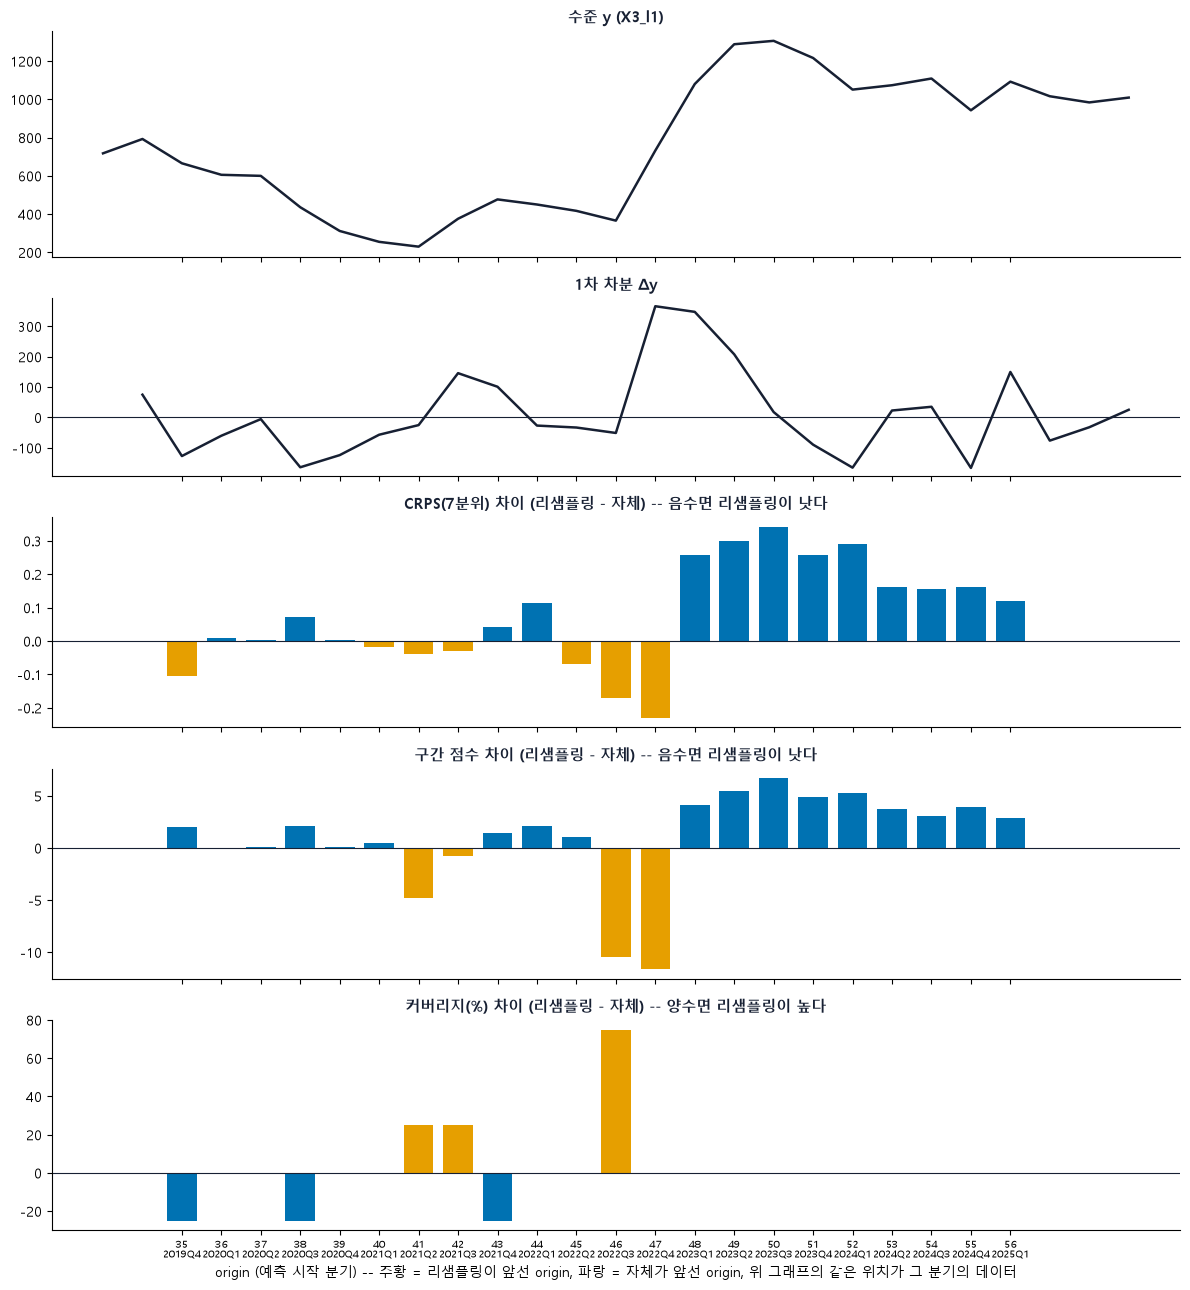

In [9]:
xl2 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.3, 1.3, 1.3]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
for ax, c, t, good_neg in [(axes[2], "CRPS(7분위)", "CRPS(7분위) 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[3], "구간점수", "구간 점수 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[4], "적중", "커버리지(%) 차이 (리샘플링 - 자체) -- 양수면 리샘플링이 높다", False)]:
    v = dif[c].values
    good = (v < 0) if good_neg else (v > 0)
    ax.bar(scored_origins, v, color=np.where(good, "#E69F00", "#0072B2"), width=0.75)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[4].set_xticks(scored_origins)
axes[4].set_xticklabels(xl2, fontsize=7)
axes[4].set_xlabel("origin (예측 시작 분기) -- 주황 = 리샘플링이 앞선 origin, 파랑 = 자체가 앞선 origin, 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


### 6-1. 같은 폭에서 비교 -- 구간 점수와 90% 도달 배율


In [10]:
LOGMODE = True


def interval_at(g, k):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if LOGMODE:
        lo_k = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        hi_k = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        lo_k, hi_k = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= lo_k) & (a <= hi_k)) * 100
    width = np.mean(hi_k - lo_k) / var_std
    iscore = np.mean((hi_k - lo_k) + (2 / ALPHA_IS) * np.maximum(lo_k - a, 0) + (2 / ALPHA_IS) * np.maximum(a - hi_k, 0)) / var_std
    return cov, width, iscore


rows = []
for name in ["리샘플링", "자체"]:
    g = DF[DF["방식"] == name]
    cov1, w1, is1 = interval_at(g, 1.0)
    ks = np.linspace(0.2, 8, 1561)
    k90 = next((k for k in ks if interval_at(g, k)[0] >= 90), np.nan)
    cov90, w90, is90 = interval_at(g, k90) if not np.isnan(k90) else (np.nan, np.nan, np.nan)
    rows.append({"방식": name, "원래 커버리지(%)": cov1, "원래 폭": w1, "원래 구간점수": is1,
                 "90% 도달 배율 k": k90, "그때의 폭": w90, "그때의 구간점수": is90})
display(pd.DataFrame(rows).set_index("방식").round(3))
print("k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.")


,원래 커버리지(%),원래 폭,원래 구간점수,90% 도달 배율 k,그때의 폭,그때의 구간점수
방식,,,,,,
리샘플링,77.273,6.164,8.271,1.545,13.196,13.745
자체,75.000,4.070,7.281,1.525,7.119,8.092


k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.


### 6-2. 결론 (로그 스케일)

**로그 스케일에서는 자체 구간이 일관되게 더 낫다.**

- **자체가 더 자주 앞선다**: CRPS 차이 평균 +0.074(리샘플링이 나쁨), 앞선 7개 대 뒤진 15개. 구간 점수도 같다(앞선 5개 대 17개).
- **급등 이후에 차이가 커진다**: origin 35~46은 리샘플링이 약간 낫지만(CRPS -0.016), 47~56은 +0.182이고 폭 차이가 4.07에 이른다.
- **같은 90%로 맞춰도 자체가 훨씬 좁다**:

| 방식 | 원래 커버리지 | 원래 구간점수 | 90% 도달 k | 그때의 폭 | 그때의 구간점수 |
|---|---|---|---|---|---|
| 리샘플링 | 77.3% | 8.27 | 1.55 | 13.20 | 13.75 |
| 자체 | 75.0% | 7.28 | 1.53 | 7.12 | 8.09 |

- 커버리지 차이는 작다(+2.3%p, 16개 origin은 같음).

**한계**: 선택된 차수가 달라 변환 효과만 분리하지 못했다. 22개 origin이 겹쳐 유의성은 검증하지 않았다.

## 7. 리샘플링 구간이 넓은 이유와 h별 특징

리샘플링 구간이 자체보다 넓은 이유를 두 가설로 본다(1: 과거 실제 오차가 모델 σ보다 크다, 2: 급등 시기의 큰 오차가 표본에 남아 이후 구간을 넓힌다). k_h는 평가가 아니라 **진단용**이다.

In [11]:
DF = logres.copy()
r = DF[DF["방식"] == "리샘플링"].set_index(["origin", "h"])
s = DF[DF["방식"] == "자체"].set_index(["origin", "h"])
sigma = s["sigma_model"]                       # 모델 σ (100 x log 단위(로그 스케일 오차))
err = 100 * (np.log(r['actual']) - np.log(r['fc']))                                    # 점예측 오차 (100 x log 단위(로그 스케일 오차))
z = err / sigma
dd = pd.DataFrame({"오차": err, "σ": sigma, "z": z, "오차표본std": r["pool_std"], "오차표본최대": r["pool_absmax"],
                   "폭비율": (np.log(r['hi']) - np.log(r['lo'])) / (np.log(s['hi']) - np.log(s['lo'])), "표본n": r["pool_n"]})
dd["표본std/σ"] = dd["오차표본std"] / dd["σ"]

print("전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ:", round(dd["표본std/σ"].mean(), 3), " / 구간 폭 비율(리샘플링÷자체):", round(dd["폭비율"].mean(), 3))
print("실제 오차(88개)의 표준편차 ÷ 모델 σ 평균:", round(dd["오차"].std() / dd["σ"].mean(), 3))


전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ: 1.098  / 구간 폭 비율(리샘플링÷자체): 1.123
실제 오차(88개)의 표준편차 ÷ 모델 σ 평균: 1.544


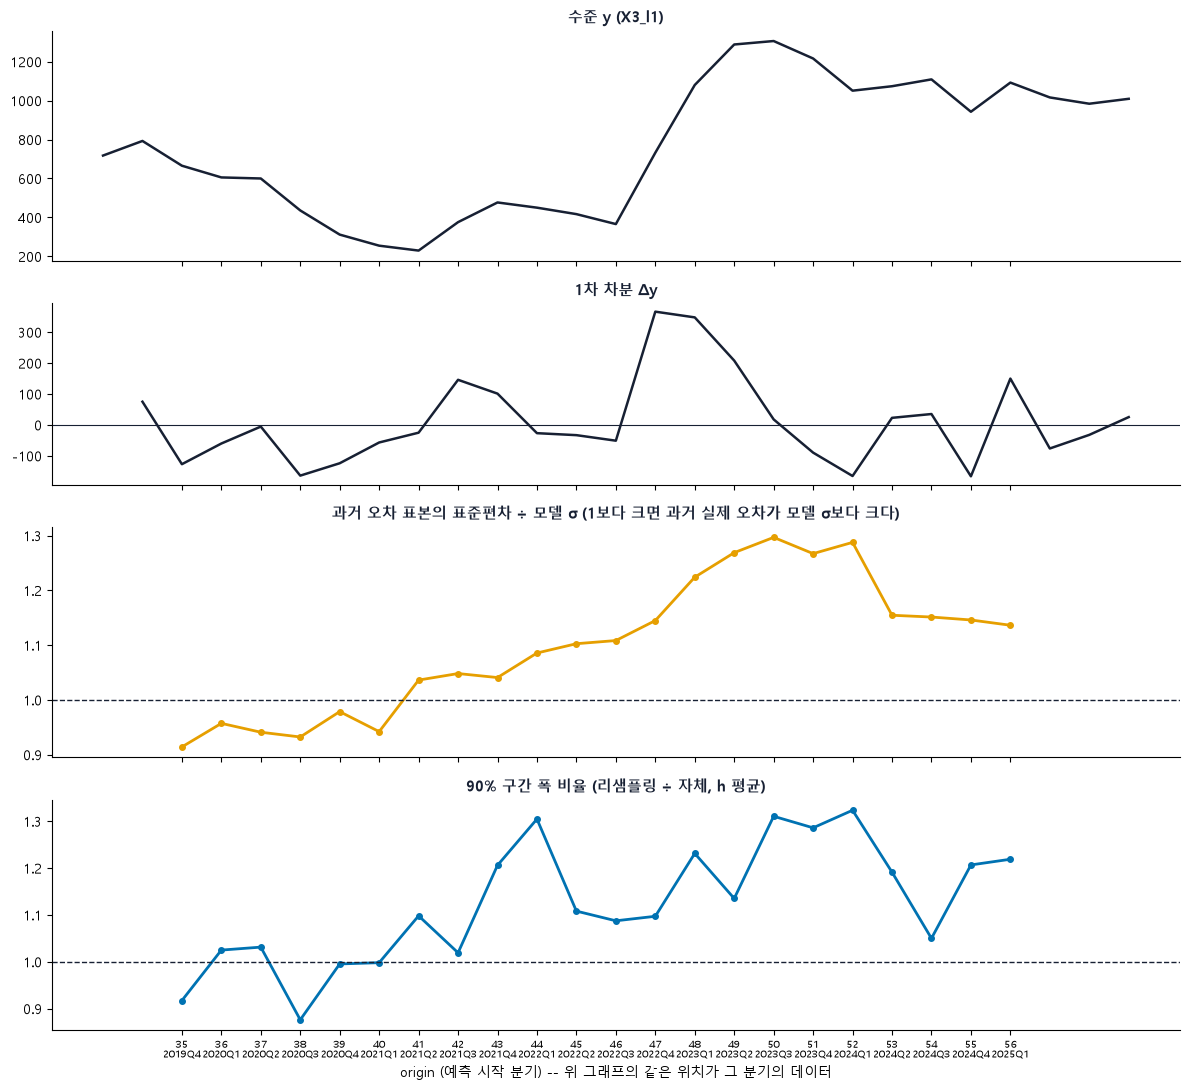

구간별 평균:


,표본std/σ,폭비율
origin 35~46,1.007,1.056
origin 47~56,1.208,1.205


In [12]:
per_o = dd.groupby("origin")[["표본std/σ", "폭비율"]].mean()
xl3 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.4, 1.4]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
axes[2].plot(scored_origins, per_o["표본std/σ"].values, marker="o", ms=4, color="#E69F00", linewidth=2)
axes[2].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[2].set_title("과거 오차 표본의 표준편차 ÷ 모델 σ (1보다 크면 과거 실제 오차가 모델 σ보다 크다)", fontsize=11, fontweight="bold", color="#172033")
axes[3].plot(scored_origins, per_o["폭비율"].values, marker="o", ms=4, color="#0072B2", linewidth=2)
axes[3].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[3].set_title("90% 구간 폭 비율 (리샘플링 ÷ 자체, h 평균)", fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl3, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()

print("구간별 평균:")
split = np.where(per_o.index <= 46, "origin 35~46", "origin 47~56")
display(per_o.groupby(split).mean().round(3))


### 7-1. h별 특징

h=1~4마다 실제 오차의 표준편차, 모델 σ, 비율, h=1 대비 증가율, 진단용 `k_h`를 본다.

,실제 오차 표준편차,모델 σ 평균,오차 표본 표준편차 평균,리샘플링÷자체 폭,k_h (진단),오차÷σ,오차 증가율(h=1=1),σ 증가율(h=1=1)
h,,,,,,,,
1,26.528,15.959,17.289,1.189,1.279,1.662,1.000,1.000
2,47.565,30.371,34.132,1.126,1.781,1.566,1.793,1.903
3,66.968,45.090,50.630,1.100,1.505,1.485,2.524,2.825
4,80.926,59.461,65.253,1.079,1.446,1.361,3.051,3.726


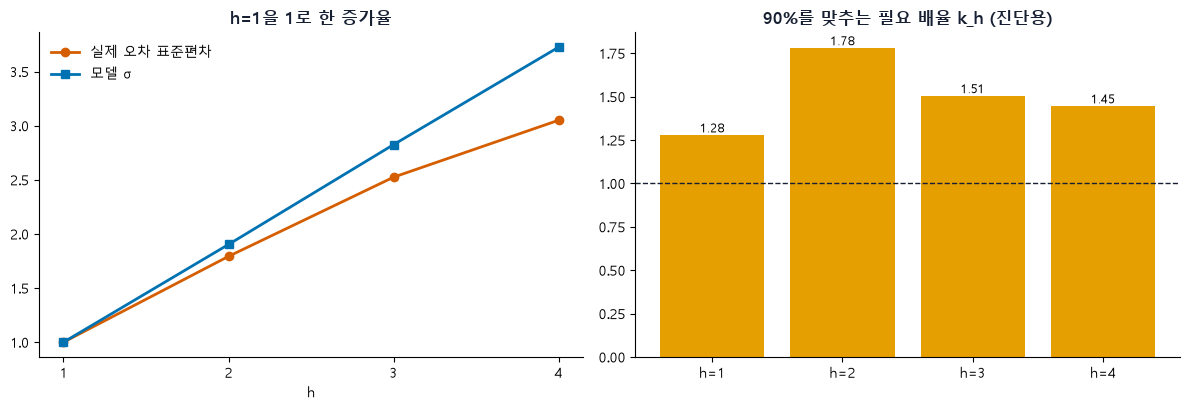

In [13]:
hg = dd.groupby("h")
htab = pd.DataFrame({
    "실제 오차 표준편차": hg["오차"].std(),
    "모델 σ 평균": hg["σ"].mean(),
    "오차 표본 표준편차 평균": hg["오차표본std"].mean(),
    "리샘플링÷자체 폭": hg["폭비율"].mean(),
    "k_h (진단)": hg["z"].apply(lambda x: np.quantile(np.abs(x), 0.9) / Z),
})
htab["오차÷σ"] = htab["실제 오차 표준편차"] / htab["모델 σ 평균"]
htab["오차 증가율(h=1=1)"] = htab["실제 오차 표준편차"] / htab["실제 오차 표준편차"].iloc[0]
htab["σ 증가율(h=1=1)"] = htab["모델 σ 평균"] / htab["모델 σ 평균"].iloc[0]
display(htab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hs = htab.index.values
axes[0].plot(hs, htab["오차 증가율(h=1=1)"], marker="o", color="#D55E00", linewidth=2, label="실제 오차 표준편차")
axes[0].plot(hs, htab["σ 증가율(h=1=1)"], marker="s", color="#0072B2", linewidth=2, label="모델 σ")
axes[0].set_xticks(hs)
axes[0].set_title("h=1을 1로 한 증가율", fontsize=12, fontweight="bold", color="#172033")
axes[0].set_xlabel("h")
axes[0].legend(frameon=False)
bars = axes[1].bar([f"h={h}" for h in hs], htab["k_h (진단)"], color="#E69F00")
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[1].set_title("90%를 맞추는 필요 배율 k_h (진단용)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 7-2. 결론 (로그 스케일)

**로그 스케일에서는 모델 σ가 더 잘 맞지만, 급등 이후 리샘플링의 과거 오차 표본이 모델 σ보다 커져 구간이 넓어진다.**

- **가설 1은 약하게 맞음**: 오차 표본 std ÷ σ가 1.10, 폭 비율 1.12(원 스케일은 1.29, 1.31). 로그에서는 모델 σ가 과거 오차와 더 가깝다.
- **가설 2는 맞음**: 급등 전(origin 35~46)은 1.01(폭 1.06), 이후(47~56)는 1.21(폭 1.21)로 벌어진다.
- **실제 오차**: 평가 구간 실제 오차 std가 모델 σ의 1.54배(원 스케일 2.07배). 로그에서 σ 과소가 더 작다.
- **h별**:

| h | 오차÷σ | 오차 증가율 | σ 증가율 | k_h (진단) |
|---|---|---|---|---|
| 1 | 1.66 | 1.00 | 1.00 | 1.28 |
| 2 | 1.57 | 1.79 | 1.90 | 1.78 |
| 3 | 1.49 | 2.52 | 2.83 | 1.51 |
| 4 | 1.36 | 3.05 | 3.73 | 1.45 |

  원 스케일과 같은 모양이다. σ는 h가 클수록 오차보다 빨리 커져서(h=4: 3.73배 vs 3.05배) 오차÷σ가 줄어든다.

**한계**: 선택된 차수가 달라 변환 효과만 분리하지 못했다. 22개 origin이 겹쳐 유의성 검정은 하지 않았다.